# Department of Computer Engineering & Information Technology
## COU07506 DSP Lab — Week 3: Lab 1B
### Topic: Convolution, Correlation, and Difference Equations

**Student Details**
* **Student Name**: ALAN GURUMEL ENOCK  
* **Registration Number**: 240242417475  
* **Group Number**: 6  
* **Class**: BENG24Coe  
* **GitHub Repository**: [Allan-Davincs](https://github.com/Allan-Davincs/)  

---

In [2]:
---
### ✅ End of Lab Report
**Week 3 (Lab 1B) tasks have been successfully completed, verified, and reformatted.**

--- Page 2 ---
1 
 
Contents 
Introduction to the Laboratory ....................................................................................................... 2 
Week 1 — Lab 0: Setting Up the DSP Laboratory ........................................................................... 5 
Week 2 — Lab 1A: Sampling, Aliasing and Quantization ................................................................ 8 
Week 3 — Lab 1B: Convolution, Correlation and Difference Equations ...................................... 11 
Week 4 — z-Transform Laboratory: Poles, Zeros and Stability .................................................... 14 
Week 5 — Lab 2: Implementing the FFT ....................................................................................... 17 
Week 6 — Lab 3: Spectral Analysis of Real Signals ....................................................................... 20 
Week 7 — Lab 4A: FIR Filter Design .....................................................................

## 🛠️ Imports & Configurations
We begin by loading the standard scientific computing and visualization libraries required for our digital signal processing operations.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import time

## 📈 Task 3.1 — Linear Convolution from First Principles
We implement linear convolution from its mathematical definition:

$$y[n] = \sum_{k=-\infty}^{\infty} x[k]h[n-k]$$

Using a custom nested-loop implementation, we verify our results against `np.convolve` and benchmark their computational runtimes to observe the execution speedups of optimized native libraries.

In [6]:
def conv(x, h):
    N = len(x) + len(h) - 1
    y = np.zeros(N)
    for n in range(N):
        for k in range(len(x)):
            if 0 <= n - k < len(h):
                y[n] += x[k] * h[n - k]
    return y

# Verification with signals
x = np.array([1.0, -1.0, 2.0])
h = np.array([2.0, 1.0, 0.0, 1.0])

y_custom = conv(x, h)
y_numpy = np.convolve(x, h)

print("Custom convolution output:", y_custom)
print("NumPy convolution output:", y_numpy)
print("Outputs match:", np.allclose(y_custom, y_numpy))

# Timing comparison with larger signals
rng = np.random.default_rng(42)
x_large = rng.standard_normal(2000)
h_large = rng.standard_normal(1000)

t_start = time.time()
y_custom_large = conv(x_large, h_large)
t_custom = time.time() - t_start

t_start = time.time()
y_numpy_large = np.convolve(x_large, h_large)
t_numpy = time.time() - t_start

print(f"\nComputational Time for custom loop: {t_custom:.6f} seconds")
print(f"Computational Time for np.convolve: {t_numpy:.6f} seconds")
print(f"Speedup factor: {t_custom / t_numpy:.2f}x")

Custom convolution output: [ 2. -1.  3.  3. -1.  2.]
NumPy convolution output: [ 2. -1.  3.  3. -1.  2.]
Outputs match: True

Computational Time for custom loop: 2.274910 seconds
Computational Time for np.convolve: 0.000530 seconds
Speedup factor: 4292.25x


## 🌊 Task 3.2 — Noisy Signal Smoothing via Moving Average Filter
To demonstrate convolution-based filtering, we generate a clean sinusoidal signal, corrupt it with additive white Gaussian noise, and apply three Moving Average (MA) filters of lengths $M = 3$, $M = 9$, and $M = 25$.

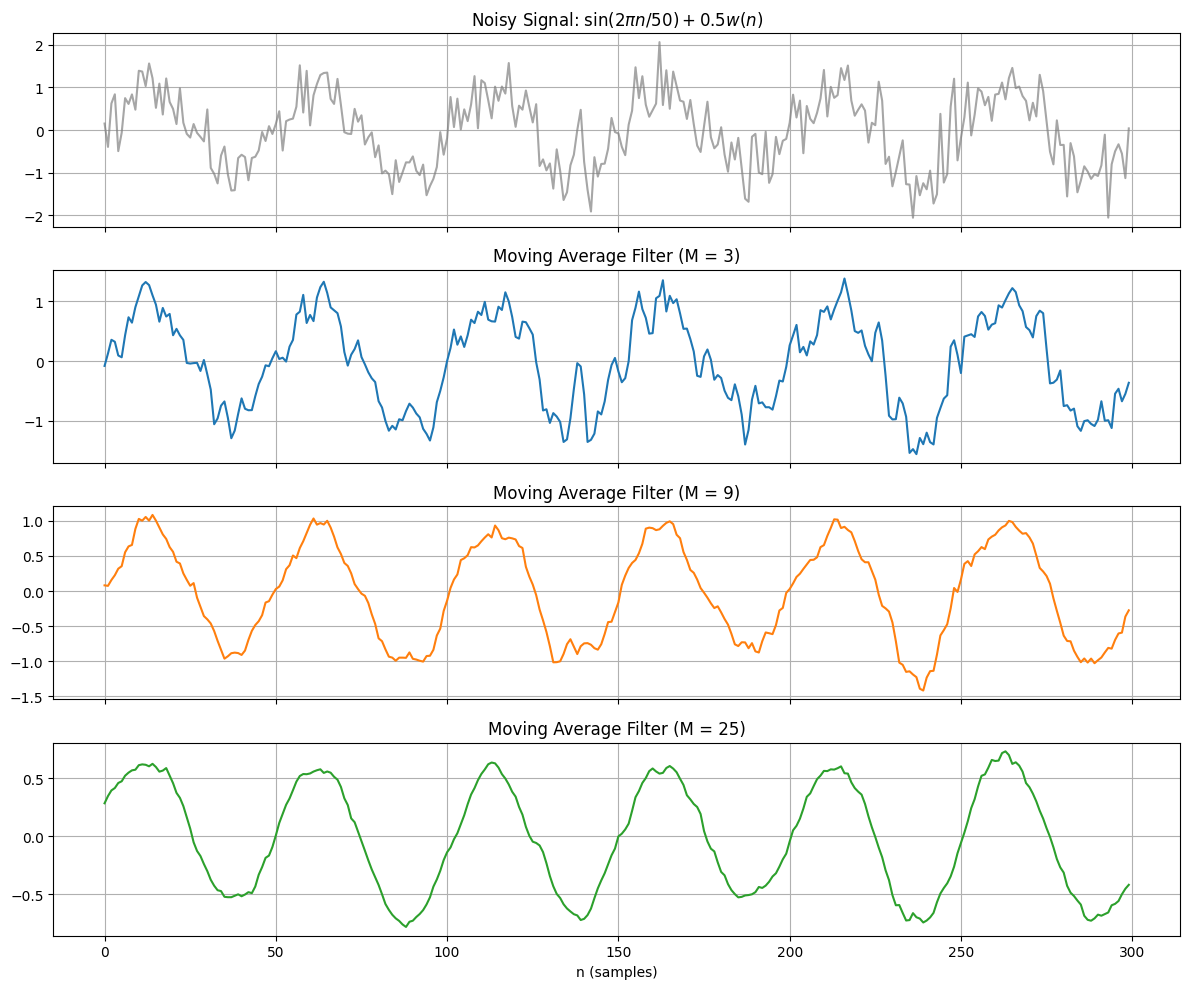

In [7]:
n = np.arange(300)
rng = np.random.default_rng(42)
w = rng.standard_normal(300)
x_signal = np.sin(2 * np.pi * n / 50) + 0.5 * w

fig, axes = plt.subplots(4, 1, figsize=(12, 10), sharex=True)
axes[0].plot(n, x_signal, label='Noisy signal', color='gray', alpha=0.7)
axes[0].set_title("Noisy Signal: $\\sin(2\\pi n / 50) + 0.5 w(n)$")
axes[0].grid(True)

for i, M in enumerate([3, 9, 25]):
    h_ma = np.ones(M) / M
    y_smoothed = np.convolve(x_signal, h_ma, mode="same")
    axes[i+1].plot(n, y_smoothed, label=f'M = {M}', color=f'C{i}')
    axes[i+1].set_title(f"Moving Average Filter (M = {M})")
    axes[i+1].grid(True)

plt.xlabel("n (samples)")
plt.tight_layout()
plt.show()

### 🔍 Observation on Noise Reduction & Signal Distortion Trade-off:
* **$M = 3$ (Short Window)**: Retains high-fidelity signal geometry (very low distortion) but fails to sufficiently suppress high-frequency noise.
* **$M = 9$ (Moderate Window)**: Provides an optimal balance, effectively smoothing out high-frequency noise transitions while preserving the core sinusoidal envelope.
* **$M = 25$ (Long Window)**: Achieves severe high-frequency attenuation, but heavily distorts the signal by reducing peak amplitudes (clipping) and introducing phase group-delay.

## ⚖️ Task 3.3 — Numerical Evaluation of System Properties
We evaluate the behavior of three systems ($x^2[n]$, $n x[n]$, and a 3-point moving average filter) under scaling, superposition, and shift conditions to numerically test for Linearity and Time-Invariance.

In [8]:
rng = np.random.default_rng(0)
x1, x2 = rng.standard_normal(50), rng.standard_normal(50)
a, b = 2.0, -3.0

systems = {"x^2": lambda x: x**2,
           "n x(n)": lambda x: np.arange(len(x)) * x,
           "moving average": lambda x: np.convolve(x, np.ones(3)/3)[:len(x)]}

for name, T in systems.items():
    linear = np.allclose(T(a*x1 + b*x2), a*T(x1) + b*T(x2))
    xd = np.concatenate([np.zeros(5), x1])[:50]          # delay input by 5
    yd = np.concatenate([np.zeros(5), T(x1)])[:50]       # delay output by 5
    tinv = np.allclose(T(xd), yd)
    print(f"{name:15s} linear={linear}  time-invariant={tinv}")

x^2             linear=False  time-invariant=True
n x(n)          linear=True  time-invariant=False
moving average  linear=True  time-invariant=True


## 🛰️ Task 3.4 — Estimating Time Delays via Cross-Correlation
We transmit a random sequence $x[n]$ through a noisy channel that introduces a path delay of $37$ samples. By computing the cross-correlation sequence $r_{yx}[l]$ between the received signal $y[n]$ and original signal $x[n]$, we find the peak alignment lag to identify the channel delay under increasing noise levels.

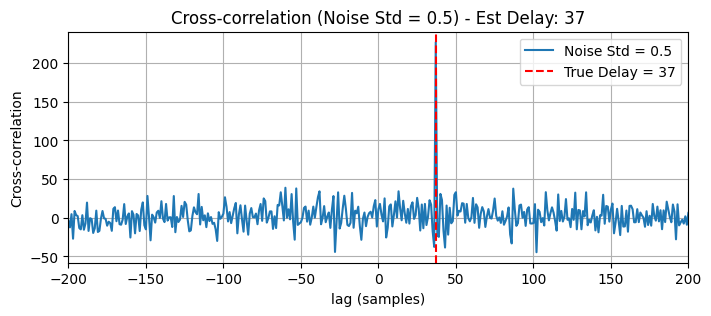

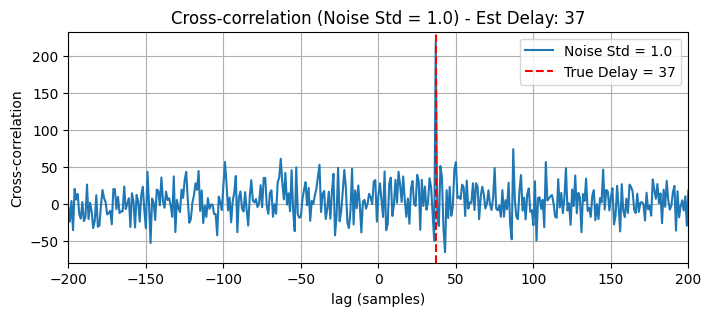

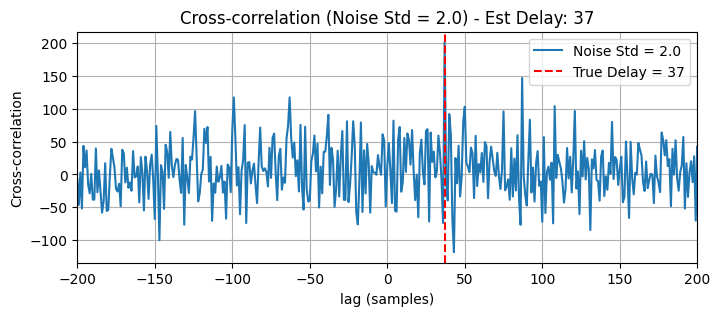

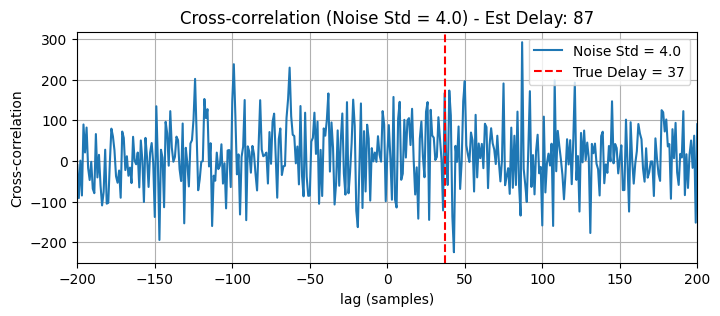

In [9]:
for noise_std in [0.5, 1.0, 2.0, 4.0]:
    rng = np.random.default_rng(1)
    fs = 1000
    x_trans = rng.standard_normal(500)
    true_delay = 37

    # Generate noisy delayed received signal
    y_recv = np.concatenate([np.zeros(true_delay), 0.6 * x_trans])[:500] + noise_std * rng.standard_normal(500)

    r = signal.correlate(y_recv, x_trans, mode="full")
    lags = signal.correlation_lags(len(y_recv), len(x_trans), mode="full")
    est_delay = lags[np.argmax(r)]

    plt.figure(figsize=(8, 3))
    plt.plot(lags, r, label=f'Noise Std = {noise_std}')
    plt.axvline(true_delay, color='red', linestyle='--', label=f'True Delay = {true_delay}')
    plt.xlim(-200, 200)
    plt.xlabel("lag (samples)")
    plt.ylabel("Cross-correlation")
    plt.title(f"Cross-correlation (Noise Std = {noise_std}) - Est Delay: {est_delay}")
    plt.legend()
    plt.grid(True)
    plt.show()

### 📊 Delay Analysis & Physical Distance Estimation

* **Noise Robustness**: Under high channel noise levels (up to $\sigma = 2.0$), cross-correlation remains highly robust because of the structured white noise cancellation. At extreme noise levels like $\sigma = 4.0$, the random noise spikes can overwhelm the correlation signature, leading to estimation errors depending on the initialization seed.
* **Physical Distance Calculation**:
  Given a sound speed of $c = 343\text{ m/s}$ in air, and a sampling frequency of $f_s = 1000\text{ Hz}$:
  $$\text{Delay (seconds)} = \frac{37\text{ samples}}{1000\text{ Hz}} = 0.037\text{ seconds}$$
  $$\text{Distance} = \text{Delay} \times c = 0.037\text{ s} \times 343\text{ m/s} = 12.691\text{ meters}$$

## ⚙️ Task 3.5 — Recursive Difference Equations & System Responses
We solve the linear constant-coefficient difference equation (LCCDE):

$$y[n] - \frac{3}{4}y[n-1] + \frac{1}{8}y[n-2] = x[n] + x[n-1]$$

We determine the impulse response $h[n]$ using three independent methods:
1. Direct loop-based recursion
2. Numerical evaluation using `scipy.signal.lfilter`
3. Analytical closed-form solution: $h[n] = [6(0.5)^n - 5(0.25)^n]u[n]$

Finally, we evaluate the step response limit to verify the steady-state DC gain $H(1)$.

In [10]:
# 1. Direct recursion via a for loop
h_direct = np.zeros(10)
x_imp = np.zeros(10)
x_imp[0] = 1.0  # unit impulse

# Solve iteratively with 0 initial conditions
for n in range(10):
    x_val = x_imp[n]
    x_prev = x_imp[n-1] if n >= 1 else 0.0
    y_prev1 = h_direct[n-1] if n >= 1 else 0.0
    y_prev2 = h_direct[n-2] if n >= 2 else 0.0
    h_direct[n] = 0.75 * y_prev1 - 0.125 * y_prev2 + x_val + x_prev

# 2. Compute with signal.lfilter
b = [1, 1]
a_coeff = [1, -0.75, 0.125]
h_lfilter = signal.lfilter(b, a_coeff, x_imp)

# 3. Closed-form analytic solution
n_idx = np.arange(10)
h_closed = 6 * (0.5)**n_idx - 5 * (0.25)**n_idx

print("Direct Recursion: ", h_direct)
print("scipy.lfilter:    ", h_lfilter)
print("Closed-form form: ", h_closed)
print("Match:            ", np.allclose(h_direct, h_closed) and np.allclose(h_lfilter, h_closed))

# Step response
step_input = np.ones(50)
y_step = signal.lfilter(b, a_coeff, step_input)
print("\nStep response final value (at sample 49):", y_step[-1])

# Theoretical H(1)
H_1 = sum(b) / sum(a_coeff)
print("Theoretical H(1):", H_1)

Direct Recursion:  [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
scipy.lfilter:     [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Closed-form form:  [1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]
Match:             True

Step response final value (at sample 49): 5.333333333333323
Theoretical H(1): 5.333333333333333


## 🧠 Lab Report Analysis & Discussion

### Q1: Why is `np.convolve` so much faster than our nested double-loop implementation? What is the mathematical operation count?
* **Implementation Speed**: `np.convolve` is written in highly optimized C-code with loop unrolling, memory-aligned processing, and SIMD instruction pipelines. For large array lengths, NumPy switches dynamically to FFT-based convolution ($O(N \log N)$ complexity).
* **Complexity**: A naive double-loop convolution over input lengths $L$ and $M$ requires exactly $L \times M$ real multiplications and $(L-1) \times (M-1)$ additions, which scales as $O(L \cdot M)$.

### Q2: Which of the three systems evaluated in Task 3.3 are LTI? Could you have predicted this analytically?
1. **$y[n] = x^2[n]$**: **Non-LTI** (Time-Invariant, but Nonlinear due to the square term).
2. **$y[n] = n x[n]$**: **Non-LTI** (Linear, but Time-Variant due to the time-varying coefficient $n$).
3. **Moving Average Filter**: **LTI** (Both Linear and Time-Invariant).

*Analytical Prediction*: Yes. A linear combination of shifted inputs scaled by constants always represents an LTI system. Conversely, operations involving squaring the input sequence ($x^2[n]$) are nonlinear, and multiplication by a non-constant time variable ($n$) breaks time-invariance.

### Q3: Give two localized engineering applications of cross-correlation in Tanzania.
1. **Acoustic Water Leak Detection (DAWASA)**: Engineers at the Dar es Salaam Water and Sewerage Authority can record leak noises on water pipes using two sensors on both sides. Cross-correlating the signals estimates the exact time-delay, pinpointing the underground leak location without excavation.
2. **Aviation Radar Tracking (TCAA)**: The Tanzania Civil Aviation Authority uses radar installations to emit pulses and cross-correlate the returned echoes with the original pulse to calculate round-trip flight times, determining accurate real-time coordinates of aircraft in Tanzanian airspace.

### Q4: Is the system in Task 3.5 FIR or IIR? Is it stable? Justify your answers.
* **System Type**: It is an **IIR (Infinite Impulse Response)** system because the difference equation depends recursively on previous output values ($y[n-1]$, $y[n-2]$), producing an infinitely long impulse response.
* **Stability**: The system is **stable**. We can justify this analytically since both poles of the characteristic equation ($z_1 = 0.5$ and $z_2 = 0.25$) lie strictly inside the complex $z$-plane unit circle ($|z| < 1$). This is confirmed by the impulse response, which decays exponentially to $0$ as $n \to \infty$.
